The gofigr extension is already loaded. To reload it, use:
  %reload_ext gofigr



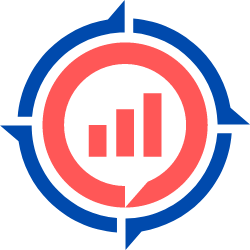

In [94]:
import pandas as pd 
import numpy as np
import mwtab
import sys,os
sys.path.append(os.path.abspath("/users/j/a/jaileru/metabolomics-toolkit/"))
from dimensionality_reduction import *

import plotly.io as pio
pio.renderers.default = "iframe"

%load_ext gofigr
from gofigr.jupyter import *

configure(analysis=FindByName("AnalysisPlanST002118-06082026", create=True), 
          auto_publish=True)

In [95]:
untargeted_data = pd.read_parquet("../data/reference_copy_untargeted_data.parquet")
categorical_data = pd.read_parquet("../data/reference_copy_categorical_data.parquet")

## Getting to know the Data (Data Inventory)

In [96]:
varlist = categorical_data.columns.tolist()
columns_of_interest = [x for x in varlist if "ID" not in x]
categorical_data.loc[:,columns_of_interest]
categorical_data = categorical_data[categorical_data.index.str.contains("_S_")]

In [97]:
summary_stats_table = []
for col in categorical_data.columns:
    if col.startswith('Blood'):
        summary_stats_table.append(categorical_data[col].astype(float).describe())
summary_stats_table = pd.concat(summary_stats_table,axis=1).iloc[:,1:]
summary_stats_table

,BloodAl,BloodMn,BloodFe,BloodSe,BloodCd,BloodSn,BloodHg,BloodPb
count,27.000000,27.000000,27.000000,27.000000,27.000000,27.000000,27.000000,27.000000
mean,17.756860,22.745945,382924.483775,222.809143,0.328052,1.457183,3.858683,6.594193
std,15.625854,8.401876,70419.722417,34.214659,0.147392,0.879299,2.513468,8.911215
min,3.933595,12.437448,268431.699952,170.551456,0.144995,0.505251,1.044791,1.022074
25%,9.350151,15.566429,318884.871145,208.980043,0.225192,0.680568,1.742658,1.918968
50%,14.757341,22.630722,373331.098644,217.972782,0.286025,0.890049,2.999917,2.760432
75%,18.905281,28.715637,441770.338384,246.742450,0.405649,2.507917,5.493449,6.470101
max,64.609550,36.479984,474107.510960,301.582308,0.688562,2.802553,9.247314,33.883422


In [98]:
data_dictionary = pd.read_excel("../info/Data Dictionary.xlsx",sheet_name='Prenatal').iloc[1:,:]
prenatal_varnames = data_dictionary['VARIABLE NAME'].str.strip().dropna().to_list()

data_dictionary = pd.read_excel("../info/Data Dictionary.xlsx",sheet_name='Exposure').iloc[1:,:]
exposure_varnames = data_dictionary["VARIABLE NAME"].str.strip().dropna().to_list()

data_dictionary = pd.read_excel("../info/Data Dictionary.xlsx",sheet_name='Dietary').iloc[1:,:]
dietary_varnames = data_dictionary['VARIABLE NAME '].str.strip().dropna().to_list()

data_dictionary = pd.read_excel("../info/Data Dictionary.xlsx",sheet_name='Birth Outcomes')
birth_outcomes_varnames = data_dictionary['VARIABLE NAME'].str.strip().dropna().to_list()

data_dictionary = pd.read_excel("../info/Data Dictionary.xlsx",sheet_name='Biospecimen')
biospecimen_varnames = data_dictionary["VARIABLE NAME"].str.strip().dropna().to_list()

data_dictionary = pd.read_excel("../info/Data Dictionary.xlsx",sheet_name='12 months').iloc[1:,:]
twelve_months_varnames = data_dictionary['VARIABLE NAME '].str.strip().dropna().to_list()

varnames = {"PRENATAL":prenatal_varnames,
            "EXPOSURE":exposure_varnames,
            "BIRTHOUTCOMES":birth_outcomes_varnames,
            "DIETARY":dietary_varnames,
            "BIOSPECIMEN":biospecimen_varnames,
            "12MONTHS":twelve_months_varnames
}

In [99]:
# A Good amount of Prenatal Information Available
prenatal_info = categorical_data.loc[:,categorical_data.columns.isin(varnames.get("PRENATAL"))].copy()

# A Good amount of Birth OutComes Information Available
birth_outcomes_info = categorical_data.loc[:,categorical_data.columns.isin(varnames.get("BIRTHOUTCOMES"))].copy()

# No Exposure Info Available
exposure_info = categorical_data.loc[:,categorical_data.columns.str.strip().isin(varnames.get("EXPOSURE"))]

# No Dietary Info Available
dietary_info = categorical_data.loc[:,categorical_data.columns.isin(varnames.get("DIETARY"))]

# 27 Blood Metals Data
biospecimen_info = categorical_data.loc[:,categorical_data.columns.isin(varnames.get("BIOSPECIMEN"))]

# No Twelve Months Info Available 
twelve_months_info = categorical_data.loc[:,categorical_data.columns.isin(varnames.get("12MONTHS"))]

# Around 150-160 columns not found in the data dictionary 
all_known = set().union(*(varnames.get(k) or [] for k in ["PRENATAL", "EXPOSURE", "DIETARY","BIRTHOUTCOMES", "BIOSPECIMEN", "12MONTHS"]))
len(categorical_data.columns[~categorical_data.columns.isin(all_known)])

167

In [100]:
prenatal_dd = pd.DataFrame(prenatal_info.notna().any(axis=0))
birth_outcomes_dd = pd.DataFrame(birth_outcomes_info.notna().any(axis=0))
print(prenatal_dd.shape)
print(birth_outcomes_dd.shape)

(21, 1)
(9, 1)


In [101]:
prenatal_var_description = {}
prenatal_var_code = {}

birth_outcomes_var_description = {}
birth_outcomes_var_code = {}

data_dictionary1 = pd.read_excel("../info/Data Dictionary.xlsx",sheet_name='Prenatal').iloc[1:,:]
data_dictionary2 = pd.read_excel("../info/Data Dictionary.xlsx",sheet_name='Birth Outcomes').iloc[1:,:]

for index,row in data_dictionary1.dropna(subset='VARIABLE NAME').iterrows():
    prenatal_var_description[row['VARIABLE NAME'].strip()] = row['VARIABLE DESCRIPTION ']
    prenatal_var_code[row['VARIABLE NAME'].strip()] = str(row["CODES"])

for index,row in data_dictionary2.dropna(subset='VARIABLE NAME').iterrows():
    birth_outcomes_var_description[row['VARIABLE NAME'].strip()] = row['VARIABLE DESCRIPTION ']
    birth_outcomes_var_code[row['VARIABLE NAME'].strip()] = str(row['CODES'])
    

In [102]:
prenatal_dd.columns = ["FoundInSubject"]
prenatal_dd['Variable Description'] = prenatal_dd.index.map(prenatal_var_description)

birth_outcomes_dd.columns = ['FoundInSubject']
birth_outcomes_dd['Variable Description'] = birth_outcomes_dd.index.map(birth_outcomes_var_description)

In [103]:
biospecimen_info = categorical_data.loc[:,categorical_data.columns.isin(varnames.get("BIOSPECIMEN"))]
biospecimen_info.dropna().describe()

,Blood,BloodAl,BloodMn,BloodFe,BloodSe,BloodCd,BloodSn,BloodHg,BloodPb
count,27.0,27.000000,27.000000,27.000000,27.000000,27.000000,27.000000,27.000000,27.000000
mean,1.0,17.756860,22.745945,382924.483775,222.809143,0.328052,1.457183,3.858683,6.594193
std,0.0,15.625854,8.401876,70419.722417,34.214659,0.147392,0.879299,2.513468,8.911215
min,1.0,3.933595,12.437448,268431.699952,170.551456,0.144995,0.505251,1.044791,1.022074
25%,1.0,9.350151,15.566429,318884.871145,208.980043,0.225192,0.680568,1.742658,1.918968
50%,1.0,14.757341,22.630722,373331.098644,217.972782,0.286025,0.890049,2.999917,2.760432
75%,1.0,18.905281,28.715637,441770.338384,246.742450,0.405649,2.507917,5.493449,6.470101
max,1.0,64.609550,36.479984,474107.510960,301.582308,0.688562,2.802553,9.247314,33.883422


### Birth Outcomes

In [104]:
def make_outcome_table(df, outcome_col):
    return (df.groupby(['Trimester_n', outcome_col],dropna=False)
              .size()
              .unstack('Trimester_n'))

In [105]:
timepoint1 = categorical_data[categorical_data['Trimester_n'] == 1]
timepoint2 = categorical_data[categorical_data['Trimester_n'] == 3]
timepoint_dict = {}
for index in birth_outcomes_dd.index:
    t1 = timepoint1.loc[:,index].notna().sum()
    t2 = timepoint2.loc[:,index].notna().sum()
    timepoint_dict[index] = {'t1':t1,'t2':t2}
birth_outcomes_info_by_timepoint = pd.DataFrame(timepoint_dict).T
birth_outcomes_info_by_timepoint.columns = ['Trimester1',"Trimester3"]
birth_outcomes_info_by_timepoint['Variable Description'] = birth_outcomes_info_by_timepoint.index.map(birth_outcomes_var_description)
birth_outcomes_info_by_timepoint

,Trimester1,Trimester3,Variable Description
b028a,332,330,Status at birth
b030a,331,329,Gender baby
b031,330,328,Birth weight (in grams)
b031a,330,328,birthweight <2500 grams
b034b,324,322,"If yes, what was the gestational age? (please,..."
b034c,324,322,preterm birth <37.0 weeks
b035b,332,330,APGAR score at 5 min
b035d,332,330,apgar score <7 at 5 minutes
b040,325,323,adverse birth outcomes


In [106]:
prenatal_info['Trimester_n'] = categorical_data.loc[prenatal_info.index,"Trimester_n"]
prenatal_info = prenatal_info[prenatal_info.index.str.contains("_S_")]

prenatal = {row['index']:row['Variable Description'] for idx,row in prenatal_dd.reset_index().iterrows()}
tables = []
for col, label in prenatal.items():
    if not (prenatal_var_code[col] == '1'):
        print(f'{col}:{prenatal_var_code[col]}')
        continue
    t = make_outcome_table(prenatal_info, col)
    t.index = pd.MultiIndex.from_tuples([(label, str(v)) for v in t.index], names=['Outcome', 'Value'])
    tables.append(t)
prenatal_categorical_info_per_timepoint = pd.concat(tables)

v107:numeric
v109:numeric
v111c:numeric
v114a:numeric
v114b:numeric
v118a:numeric
v118b:numeric


In [107]:
birth_outcomes_info['Trimester_n'] = categorical_data.loc[birth_outcomes_info.index,'Trimester_n'].copy()
birth_outcomes_info = birth_outcomes_info[birth_outcomes_info.index.str.contains("_S_")]
birth_outcomes_info['v108a'] = prenatal_info.loc[birth_outcomes_info.index,"v108a"]
outcomes = {
    'b028a': 'Live vs Still Birth',
    'b030a': 'Gender Baby',
    'b031a': 'LBW vs nBW',
    'b040':  'Adverse Birth Outcome',
    'b034c': 'Preterm Birth (<37 weeks)',
    'b035b': "APGAR score at 5 min",
    'b035d': "APGAR score <7 at 5 minutes"
}
district_map = {1.0:"Paramaribo",
                2.0: "Wanica",
                3.0: "Commewijne",
                4.0: "Marowijne",
                5.0: "Saramacca",
                6.0 : "Coronie",
                7.0: "Nickerie",
                8.0: "Para",
                9.0: "Brokopondo",
                10.0: "Sipaliwini"
}

In [118]:
# Scope-aligned version of birth_outcomes_info_by_timepoint:
# restricted to subjects with a known district (v108a), matching the per-village tables
known_idx = birth_outcomes_info[birth_outcomes_info['v108a'].isin(district_map.keys())].index

timepoint1_known = categorical_data.loc[known_idx][categorical_data.loc[known_idx, 'Trimester_n'] == 1]
timepoint3_known = categorical_data.loc[known_idx][categorical_data.loc[known_idx, 'Trimester_n'] == 3]

timepoint_dict_known = {}
for col in birth_outcomes_dd.index:
    timepoint_dict_known[col] = {
        't1': timepoint1_known[col].notna().sum(),
        't2': timepoint3_known[col].notna().sum(),
    }

birth_outcomes_info_by_timepoint_known = pd.DataFrame(timepoint_dict_known).T
birth_outcomes_info_by_timepoint_known.columns = ['Trimester1', 'Trimester3']
birth_outcomes_info_by_timepoint_known['Variable Description'] = birth_outcomes_info_by_timepoint_known.index.map(birth_outcomes_var_description)
birth_outcomes_info_by_timepoint_known

,Trimester1,Trimester3,Variable Description
b028a,331,329,Status at birth
b030a,330,328,Gender baby
b031,329,327,Birth weight (in grams)
b031a,329,327,birthweight <2500 grams
b034b,323,321,"If yes, what was the gestational age? (please,..."
b034c,323,321,preterm birth <37.0 weeks
b035b,331,329,APGAR score at 5 min
b035d,331,329,apgar score <7 at 5 minutes
b040,324,322,adverse birth outcomes


In [135]:
tables = {}
for village in district_map.keys():
    subset = birth_outcomes_info[birth_outcomes_info['v108a'] == village]
    subtable = []
    for outcome in outcomes.keys():
        outs = make_outcome_table(subset, outcome)
        subtable.append(outs)
    df = pd.concat(subtable, keys=outcomes.keys())  # <-- adds outcome name as outer index level
    tables[district_map[village]] = df
    

In [137]:
counts = []
for i in tables.keys():
    counts.append(tables[i].loc['b030a',:])
df = pd.concat(counts).groupby(level=0,dropna=False).sum()
print(df)
print("\n")
counts = []
for i in tables.keys():
    counts.append(tables[i].loc['b031a',:])
df = pd.concat(counts).groupby(level=0,dropna=False).sum()
print(df)
print("\n")
counts = []
for i in tables.keys():
    counts.append(tables[i].loc['b034c',:])
df = pd.concat(counts).groupby(level=0,dropna=False).sum()
print(df)
print("\n")
counts = []
for i in tables.keys():
    counts.append(tables[i].loc['b035b',:])
df = pd.concat(counts).groupby(level=0,dropna=False).sum()
print(df)
print("\n")
counts = []
for i in tables.keys():
    counts.append(tables[i].loc['b040',:])
df = pd.concat(counts).groupby(level=0,dropna=False).sum()
print(df)
print("\n")

Trimester_n  1.0  3.0
1.0          171  172
2.0          159  156
NaN            4    4


Trimester_n  1.0  3.0
1.0           26   25
2.0          303  302
NaN            5    5


Trimester_n  1.0  3.0
1.0           29   29
2.0          294  292
NaN           11   11


Trimester_n  1.0  3.0
6.0            1    1
7.0            2    2
8.0            8    8
9.0           66   66
10.0         254  252
NaN            3    3


Trimester_n  1.0  3.0
1.0           44   43
2.0          280  279
NaN           10   10




In [146]:
for i in tables:
    print(i)

Paramaribo
Wanica
Commewijne
Marowijne
Saramacca
Coronie
Nickerie
Para
Brokopondo
Sipaliwini


In [156]:
html = tables['Paramaribo'].to_html()
with open("paramaribo.html", "w") as f:
    f.write(html)

In [159]:
html = tables['Wanica'].to_html()
with open("wanica.html", "w") as f:
    f.write(html)

In [160]:
html = tables['Commewijne'].to_html()
with open("commewijne.html", "w") as f:
    f.write(html)

In [161]:
html = tables['Marowijne'].to_html()
with open("marowijne.html", "w") as f:
    f.write(html)

In [162]:
html = tables['Saramacca'].to_html()
with open("saramacca.html", "w") as f:
    f.write(html)

In [163]:
html = tables['Coronie'].to_html()
with open("coronie.html", "w") as f:
    f.write(html)

In [164]:
html = tables['Nickerie'].to_html()
with open("nickerie.html", "w") as f:
    f.write(html)

In [165]:
html = tables['Para'].to_html()
with open("para.html", "w") as f:
    f.write(html)

In [166]:
html = tables['Brokopondo'].to_html()
with open("brokopondo.html", "w") as f:
    f.write(html)

In [167]:
html = tables['Sipaliwini'].to_html()
with open("sipaliwini.html", "w") as f:
    f.write(html)